In [9]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/29/2022
# version ='1.0'

# Demo: Further Experiments on Solving A Family of LP by  Primal-Dual Interior-Point Method

In book-convex-2004, the primal-dual interior-point method was applied to the following family of LPs with different dimensions,

\begin{equation}
\begin{array}{rcl}
\text{minimize} & c^Tx \\
\text{subject to} & Ax=b, & x \succeq 0 \\ 
\end{array}
\end{equation}
where $x\in R^n, A\in R^{m\times n}$

The procedure to generate the problem parameters $A, b, c$ has been described in another demo. In this demo, it is to implement the Primal-Dual Interior-Point method to solve the above family of LPs.

Let 
$$
\begin{array}{rcl}
f_0(x) & = & c^T x \\
f(x) & = & -x \\
Df(x) & = & = -I_n \\
\end{array}
$$

The primal-dual search direction $\Delta y=(\Delta x, \Delta \lambda, \Delta \nu)$ is defined as the solution of
$$
\begin{array}{rccl}
\left[\begin{array}{ccc}
\nabla^2 f_0(x) + \displaystyle{\sum_{i=1}^m\lambda_i\nabla^2f_i(x)} & Df(x)^T & A^T \\
-diag(\lambda)Df(x) & -diag(f(x)) & 0 \\
A & 0 & 0 \\
\end{array} \right] & \left[\begin{array}{c}
\Delta x \\
\Delta \lambda \\
\Delta \nu
\end{array} \right] & = & - \left[\begin{array}{c}
r_{dual} \\
r_{cent} \\
r_{pri} \\
\end{array} \right]
\end{array}
$$
i.e.
$$
\begin{array}{rccl}
\left[\begin{array}{ccc}
0_{n\times n} & -I_n & A^T \\
diag(\lambda) & diag(x) & 0 \\
A & 0 & 0 \\ 
\end{array} \right]& \left[\begin{array}{c}
\Delta x \\
\Delta \lambda \\
\Delta \nu
\end{array} \right] & = & - \left[\begin{array}{c}
r_{dual} \\
r_{cent} \\
r_{pri} \\
\end{array} \right]
\end{array}
$$
and 
$$
\begin{array}{rllll}
r_{dual} & = & \nabla f_0(x)+Df(x)^T\lambda + A^T\nu & = & c - \lambda + A^T\nu \\
r_{cent} & = & -diag(f(x))f(x)-(1/t)\mathbf{1} & = & diag(\lambda)x-(1/t)\mathbf{1} \\
r_{pri} & = & Ax-b \\
\end{array}
$$

The following parameters are used in the demo:
$$
\begin{array}{rcl}
m & = & round(10^{1:0.1:3})\\
n & = & 2*m \\
l & = & n-m\\ 
\alpha & = & 0.01\\ 
\beta & = & 0.5\\
\epsilon & = & 1e-8 \\
\epsilon_{feas} & = & 1e-8 \\
\mu & =& 10 \\
\end{array}
$$

In [10]:
from scipy.special import exp10
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.linalg import null_space

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [11]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
 with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$

In [12]:
def get_A_b_c(m, n, l):
    """
    A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
    with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$
    :param m:
    :param n:
    :param l:
    :return:
    """
    if n != 2 * m:
        raise RuntimeError('currently only support n = 2m scenarios')

    x_asterisk = np.random.uniform(low=0, high=1, size=(n, 1))
    x_asterisk[0:l] = 0
    lambda_ = np.random.uniform(low=0, high=1, size=(n, 1))
    lambda_[l:] = 0

    B = np.zeros((n, n - l))
    E = np.zeros((n, n - l))
    for li in range(n - l):
        xe = x_asterisk.copy()
        xe[0:l] = np.random.uniform(low=0, high=1, size=(l, 1))
        xe[l + li] = 0.5 * x_asterisk[l + li]  # $x_{e,i}$
        dx = xe - x_asterisk  # $d_i=x_{e,i}-x^*$
        B[:, li] = np.squeeze(dx)
        E[:, li] = np.squeeze(xe)

    x0 = np.reshape(np.average(E, axis=1), (-1, 1))  # $x_0=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}(x_{e,i})$

    Ns_B = null_space(B.T)
    A = Ns_B[:, 0:m].T  # only the first m is selected if n=2m

    b1 = A @ x0
    b2 = A @ x_asterisk
    if not np.allclose(b1, b2):
        raise RuntimeError('x0, xp should both satisfy Ax = b')
    b = b1

    nu = np.random.normal(loc=0, scale=1, size=(m, 1))
    c = lambda_ - A.T @ nu

    return A, b, c, x_asterisk, x0, nu

solve the primal-dual search direction by direct matrix inversion

Refer to FlexibleLecture Note for details

In [13]:
def my_primal_dual_search_direction(x, lambda_, nu, t, A, b, c):
    """
    solve the primal-dual search direction by direct matrix inversion
    Refer to FlexibleLecture Note for details
    :param x:
    :param lambda_:
    :param nu:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    m, n = A.shape
    H_00 = np.zeros((n, n))
    H_01 = -np.eye(n)
    H_02 = A.T

    H_10 = np.diag(np.squeeze(lambda_))
    H_11 = np.diag(np.squeeze(x))
    H_12 = np.zeros((n, m))

    H_20 = A
    H_21 = np.zeros((m, n))
    H_22 = np.zeros((m, m))

    H = np.block([[H_00, H_01, H_02], [H_10, H_11, H_12], [H_20, H_21, H_22]])

    r_pri = A @ x - b
    r_dual = c - lambda_ + A.T @ nu
    r_cent = np.diag(np.squeeze(lambda_)) @ x - 1 / t * np.ones((n, 1))

    r = np.block([[r_dual], [r_cent], [r_pri]])

    cond = np.linalg.cond(H)
    if cond < 1e30:
        delta_y_pd = np.linalg.inv(H) @ (-r)
        delta_x_pd = delta_y_pd[0:n]
        delta_lambda_pd = delta_y_pd[n:2 * n]
        delta_nu_pd = delta_y_pd[2 * n:]
        return delta_x_pd, delta_lambda_pd, delta_nu_pd
    else:
        raise RuntimeError('H is not invertible.')

the standard backtracking line search method

Refer to section 11.7.3 in the textbook

In [14]:
def backtracking_line_search(x, lambda_, nu, delta_x_pd, delta_lambda_pd, delta_nu_pd, alpha, beta, t, args):
    """
    the standard backtracking line search method
    Refer to section 11.7.3 in the textbook
    :param x:
    :param lambda_:
    :param nu:
    :param delta_x_pd:
    :param delta_lambda_pd:
    :param delta_nu_pd:
    :param alpha:
    :param beta:
    :param t:
    :param args:
    :return:
    """
    A, b, c = args
    m, n = A.shape

    tmp = [-lambda_[i][0] / delta_lambda_pd[i][0] if delta_lambda_pd[i][0] < 0 else 1 for i in range(n)]
    s_max = min(1, np.min(tmp))
    s = 0.99 * s_max
    while True:
        x_next = x + s * delta_x_pd
        feasible = np.all(x_next > 0)
        if feasible:
            break
        else:
            s = beta * s

    r_pri = A @ x - b
    r_dual = c - lambda_ + A.T @ nu
    r_cent = np.diag(np.squeeze(lambda_)) @ x - 1 / t * np.ones((n, 1))
    r = np.block([[r_dual], [r_cent], [r_pri]])
    r_norm = np.linalg.norm(r)

    while True:
        x_next = x + s * delta_x_pd
        lambda_next = lambda_ + s * delta_lambda_pd
        nu_next = nu + s * delta_nu_pd

        r_pri_next = A @ x_next - b
        r_dual_next = c - lambda_next + A.T @ nu_next
        r_cent_next = np.diag(np.squeeze(lambda_next)) @ x_next - 1 / t * np.ones((n, 1))
        r_next = np.block([[r_dual_next], [r_cent_next], [r_pri_next]])
        r_next_norm = np.linalg.norm(r_next)

        if r_next_norm <= (1 - alpha * s) * r_norm:
            break
        else:
            s = beta * s

    return s

convergence speed (in terms of average of Newton iterations) versus different dimensions, with $n = 2m$

In [15]:
def plot_converge_speed_vs_mu(m_s, n_dial, mu, max_iteration=100):
    """
    convergence speed (in terms of average of Newton iterations) versus different dimensions, with $n = 2m$
    :return:
    """
    n_seeds = n_dial
    n_iterations = np.zeros((len(m_s), n_seeds))
    for m_i, m in enumerate(m_s):
        n = 2 * m
        if m > n:
            raise RuntimeError('it requires m > n')

        l = n - m
        for seed in range(n_seeds):
            np.random.seed(seed)
            #print('Info: running simulation for m={}, seed={}'.format(m, seed))
            A, b, c, x_asterisk, _, nu = get_A_b_c(m, n, l)

            alpha = 0.01
            beta = 0.5
            epsilon = 1e-8
            epsilon_feas = 1e-8

            x0 = np.ones((n, 1))  # re-initialization as 1
            lambda_0 = -1 / (-x0)
            nu0 = np.zeros((m, 1))
            eta_0 = -(lambda_0.T @ (-x0)).item()
            p_asterisk = (c.T @ x_asterisk).item()

            eta = eta_0
            x = x0
            lambda_ = lambda_0
            nu = nu0

            args = (A, b, c)
            iteration = 0
            success = False
            while True:
                t = mu * m / eta
                delta_x_pd, delta_lambda_pd, delta_nu_pd = my_primal_dual_search_direction(x, lambda_, nu, t, A, b, c)
                s = backtracking_line_search(x, lambda_, nu, delta_x_pd, delta_lambda_pd, delta_nu_pd, alpha, beta, t, args)
                x = x + s * delta_x_pd
                lambda_ = lambda_ + s * delta_lambda_pd
                nu = nu + s * delta_nu_pd

                eta = -(lambda_.T @ (-x)).item()
                r_pri_next = A @ x - b
                r_dual_next = c - lambda_ + A.T @ nu
                r_feas = np.block([[r_dual_next], [r_pri_next]])
                r_feas_norm = np.linalg.norm(r_feas)

                # print('Info: iteration={}, |r_feas|={}, eta={}, s={}'.format(iteration, r_feas_norm, eta, s))
                iteration += 1
                if r_feas_norm < epsilon_feas and eta < epsilon:
                    success = True
                    break
                if iteration > max_iteration:
                    break

            n_iterations[m_i][seed] = iteration
            #if success:
            #    print('Info: fp={}, {}'.format(p_asterisk, (c.T @ x).item()))

    avg_num_iter = np.average(n_iterations, axis=1)
    std_num_iter = np.std(n_iterations, axis=1)

    plt.figure(figsize=(12, 5))
    ax = plt.subplot(1, 1, 1)
    plt.errorbar(m_s, avg_num_iter, yerr=std_num_iter)
    ax.set_xscale('log')
    ax.set_xlabel(r'm')
    ax.set_ylabel(r'total iterations')
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.grid()
    plt.show()

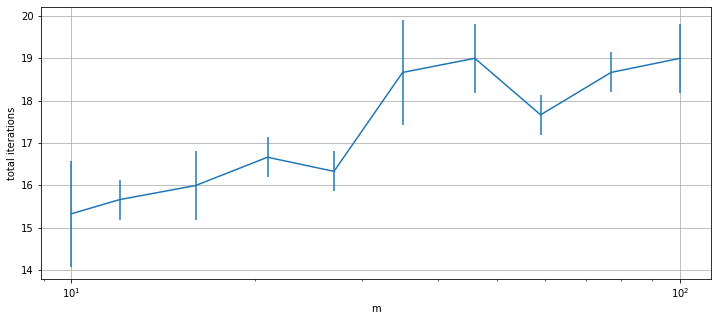

In [16]:
if __name__ == "__main__":
    plot_converge_speed_vs_mu(m_s=[int(x) for x in exp10(np.linspace(start=1, stop=2, endpoint=True, num=10))], n_dial=3, mu=10)
